<a href="https://colab.research.google.com/github/Hemanthvhb/capstone/blob/main/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Bootstrap uv and install dependencies
!pip install uv
!uv pip install --system ultralytics torch

import ultralytics
ultralytics.checks() # Verify GPU is active

# 2. Download the dataset
!git clone https://huggingface.co/datasets/LibreYOLO/weed-crop-aerial

# 3. Create the data.yaml configuration
yaml_content = """
path: /content/weed-crop-aerial
train: train/images
val: valid/images
test: test/images

names:
  0: crop
  1: weed
"""
with open('data.yaml', 'w') as f:
    f.write(yaml_content)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)
Cloning into 'weed-crop-aerial'...
remote: Enumerating objects: 2370, done.
remote: Total 2370 (delta 0), reused 0 (delta 0), pack-reused 2370 (from 1)
Receiving objects: 100% (2370/2370), 353.03 KiB | 958.00 KiB/s, done.
Resolving deltas: 100% (3/3), done.


In [ ]:
from ultralytics import YOLO

# Load standard nano model
model = YOLO('yolov8n.pt')

# Run 1 epoch to verify dataset integrity
results = model.train(data='data.yaml', epochs=1, imgsz=640)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask

ValueError: [34m[1mtrain: [0mNo labels found in /content/weed-crop-aerial/train/labels.cache. See https://docs.ultralytics.com/datasets for dataset formatting guidance.

In [ ]:
# 1. Clear the broken dataset
!rm -rf /content/weed-crop-aerial

# 2. Install Git LFS
!apt-get install git-lfs
!git lfs install

# 3. Clone the real dataset
!git clone https://huggingface.co/datasets/LibreYOLO/weed-crop-aerial

# 4. Run the baseline test
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
results = model.train(data='/content/data.yaml', epochs=1, imgsz=640)

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 52 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 2s (1,716 kB/s)
Selecting previously unselected package git-lfs.
(Reading database ... 126952 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.
Cloning into 'weed-crop-aerial'...
remote: Enumerating objects: 2370, done.
remote: Total 2370 (delta 0), reused 0 (delta 0), pack-reused 2370 (from 1)
Receiving objects: 100% (2370/2370), 353.

In [ ]:
from ultralytics import YOLO

# Load the standard lightweight YOLO model
model = YOLO('yolov8n.pt')

# Train for 20 epochs to establish the baseline performance
results = model.train(
    data='/content/data.yaml',
    epochs=20,
    imgsz=640,
    project='weed_detection',
    name='baseline_yolo'
)

# Print final baseline validation metrics
print("\n--- BASELINE METRICS ---")
print(f"mAP@0.5:      {results.box.map50}")
print(f"mAP@0.5:0.95: {results.box.map}")

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo, nbs=64, nms=None, opset=None, optimize=False, optimizer=

In [ ]:
import torch
import torch.nn as nn
from ultralytics.nn import tasks
from ultralytics.nn import modules
from ultralytics import YOLO

# 1. Define the CBAM Module
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        reduced_planes = max(1, in_planes // ratio)

        self.fc1 = nn.Conv2d(in_planes, reduced_planes, 1, bias=False)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Conv2d(reduced_planes, in_planes, 1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc2(self.relu1(self.fc1(self.avg_pool(x))))
        max_out = self.fc2(self.relu1(self.fc1(self.max_pool(x))))
        return x * self.sigmoid(avg_out + max_out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x_cat = torch.cat([avg_out, max_out], dim=1)
        return x * self.sigmoid(self.conv1(x_cat))

class CBAM(nn.Module):
    def __init__(self, c1, *args, **kwargs):
        super(CBAM, self).__init__()
        self.channel_attention = ChannelAttention(c1)
        self.spatial_attention = SpatialAttention(7)

    def forward(self, x):
        out = self.channel_attention(x)
        out = self.spatial_attention(out)
        return out

# 2. Inject CBAM into the Ultralytics namespace
modules.CBAM = CBAM
tasks.CBAM = CBAM

# 3. Create the Asymmetric Architecture YAML
yaml_content = """
nc: 2
scales:
  n: [0.33, 0.25, 1024]
backbone:
  - [-1, 1, Conv, [64, 3, 2]]  # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]] # 1-P2/4
  - [-1, 3, C2f, [128, True]]  # 2
  - [-1, 1, CBAM, [32]]        # 3: CBAM on P2 (128 * 0.25 = 32 channels)

  - [-1, 1, Conv, [256, 3, 2]] # 4-P3/8
  - [-1, 6, C2f, [256, True]]  # 5
  - [-1, 1, CBAM, [64]]        # 6: CBAM on P3 (256 * 0.25 = 64 channels)

  - [-1, 1, Conv, [512, 3, 2]] # 7-P4/16
  - [-1, 6, C2f, [512, True]]  # 8: NO CBAM

  - [-1, 1, Conv, [1024, 3, 2]]# 9-P5/32
  - [-1, 3, C2f, [1024, True]] # 10: NO CBAM
  - [-1, 1, SPPF, [1024, 5]]   # 11

head:
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 8], 1, Concat, [1]]  # cat backbone P4
  - [-1, 3, C2f, [512]]        # 14

  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 6], 1, Concat, [1]]  # cat backbone P3 (CBAM routed)
  - [-1, 3, C2f, [256]]        # 17 (P3/8-small)

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 14], 1, Concat, [1]] # cat head P4
  - [-1, 3, C2f, [512]]        # 20 (P4/16-medium)

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 11], 1, Concat, [1]] # cat head P5
  - [-1, 3, C2f, [1024]]       # 23 (P5/32-large)

  - [[17, 20, 23], 1, Detect, [nc]]  # Detect(P3, P4, P5)
"""
with open('/content/asymmetric_yolo.yaml', 'w') as f:
    f.write(yaml_content)

# 4. Train the Proposed Prototype
print("Building and Training Asymmetric CBAM Prototype...")
model = YOLO('/content/asymmetric_yolo.yaml')

results = model.train(
    data='/content/data.yaml',
    epochs=20,
    imgsz=640,
    project='weed_detection',
    name='proposed_asymmetric_cbam'
)

print("\n--- PROPOSED MODEL METRICS ---")
print(f"mAP@0.5:      {results.box.map50}")
print(f"mAP@0.5:0.95: {results.box.map}")

Building and Training Asymmetric CBAM Prototype...
WARNING ⚠️ no model scale passed. Assuming scale='n'.
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/asymmetric_yolo.yam

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/20      2.19G      5.635      9.215      4.121         47        640: 100% ━━━━━━━━━━━━ 52/52 3.5it/s 14.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.8it/s 2.9s
                   all        235       1605          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/20      2.74G      5.095      6.456       3.85        173        640: 1% ──────────── 1/52 2.7it/s 0.2s<19.1s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/20      2.74G      4.228      5.429      2.859         53        640: 100% ━━━━━━━━━━━━ 52/52 4.4it/s 11.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.8it/s 2.9s
                   all        235       1605    0.00101     0.0343   7.47e-05   1.82e-05

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      2.74G      3.451      3.314      2.009        214        640: 1% ──────────── 1/52 2.2it/s 0.2s<23.3s

...

      18/20      2.74G      1.903      1.552      1.169         43        640: 100% ━━━━━━━━━━━━ 52/52 4.8it/s 10.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.4s
                   all        235       1605      0.399       0.49      0.415      0.209

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      19/20      2.74G      2.113      1.598      1.221         80        640: 0% ──────────── 0/52  0.2s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      19/20      2.74G      1.911      1.509      1.171         35        640: 100% ━━━━━━━━━━━━ 52/52 5.0it/s 10.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.3it/s 2.4s
                   all        235       1605      0.541      0.547      0.458      0.235

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      20/20      2.74G      1.921      1.506      1.278         68        640: 1% ──────────── 1/52 1.8it/s 0.3s<28.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      20/20      2.74G      1.893      1.504      1.167         30        640: 100% ━━━━━━━━━━━━ 52/52 4.9it/s 10.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.3it/s 2.4s
                   all        235       1605      0.456      0.542      0.459      0.231

20 epochs completed in 0.081 hours.
Optimizer stripped from /content/runs/detect/weed_detection/proposed_asymmetric_cbam/weights/last.pt, 6.3MB
Optimizer stripped from /content/runs/detect/weed_detection/proposed_asymmetric_cbam/weights/best.pt, 6.3MB

Validating /content/runs/detect/weed_detection/proposed_asymmetric_cbam/weights/best.pt...
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
asymmetric_YOLO summary (fused): 88 layers, 3,006,874 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.5it/s 5.3s
                   all   

--- BASELINE DETECTION ---

image 1/1 /content/weed-crop-aerial/valid/images/33097_jpg.rf.d7736757ed5382e4111d70502d4f627d.jpg: 640x640 9 weeds, 29.2ms
Speed: 2.2ms preprocess, 29.2ms inference, 4.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/weed_detection/inference_baseline-4

--- PROPOSED MODEL DETECTION ---

image 1/1 /content/weed-crop-aerial/valid/images/33097_jpg.rf.d7736757ed5382e4111d70502d4f627d.jpg: 640x640 8 weeds, 15.4ms
Speed: 3.0ms preprocess, 15.4ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/weed_detection/inference_proposed-4

BASELINE:


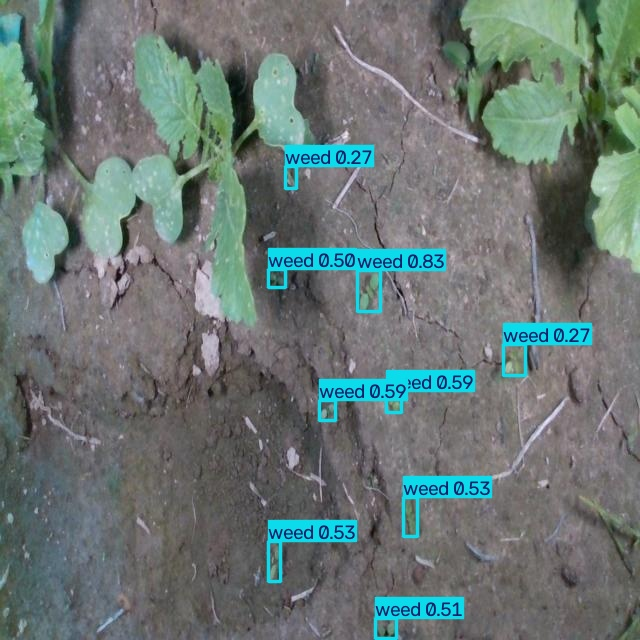


PROPOSED ASYMMETRIC:


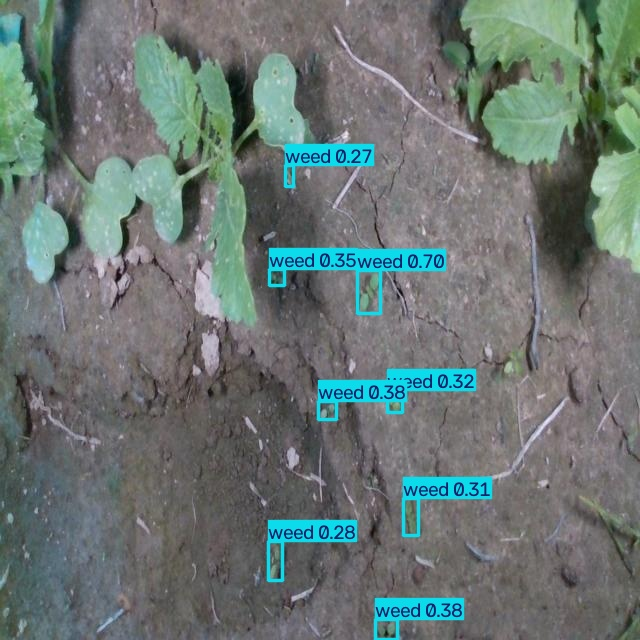

In [ ]:
import os
import glob
from IPython.display import Image, display

# 1. Pick a random test image from the validation set
test_image = glob.glob('/content/weed-crop-aerial/valid/images/*.jpg')[0]
image_name = os.path.basename(test_image)

# 2. Run Baseline Inference
print("--- BASELINE DETECTION ---")
baseline_model = YOLO('/content/runs/detect/weed_detection/baseline_yolo/weights/best.pt')
baseline_results = baseline_model.predict(source=test_image, save=True, project='weed_detection', name='inference_baseline')

# 3. Run Proposed Model Inference
print("\n--- PROPOSED MODEL DETECTION ---")
proposed_model = YOLO('/content/runs/detect/weed_detection/proposed_asymmetric_cbam/weights/best.pt')
proposed_results = proposed_model.predict(source=test_image, save=True, project='weed_detection', name='inference_proposed')

# 4. Display Results Dynamically
baseline_result = f"{baseline_results[0].save_dir}/{image_name}"
proposed_result = f"{proposed_results[0].save_dir}/{image_name}"

print("\nBASELINE:")
display(Image(filename=baseline_result, width=600))
print("\nPROPOSED ASYMMETRIC:")
display(Image(filename=proposed_result, width=600))